# Long-only 2 de 5 ações — notebook modular (v1)

O código está em `src/long_only_v1/`. Este notebook só **chama** as funções e mostra os resultados.
Cole aqui os seus textos (premissas, análises, conclusões) entre as células.

In [1]:
# Setup
%load_ext autoreload
%autoreload 2

from pathlib import Path

import numpy as np
import pandas as pd

from long_only_v1.config import TICKERS, START_DATE, END_DATE, TRAIN_END, RF_MONTHLY
from long_only_v1.data import download_prices, validate_prices
from long_only_v1 import returns as R, metrics as M, strategy as S, costs as C, robustness as RB, plots as P

P.set_style()
pd.set_option("display.max_columns", 10)

# O notebook fica em notebooks/, os resultados em results/v1/
RESULTS = Path.cwd().parent / "results" / "v1"
FIGS = RESULTS / "figures"
TABLES = RESULTS / "tables"
TABLES.mkdir(parents=True, exist_ok=True)

## 1. Dados

Primeira data: 2013-01-02 | Última data: 2026-09-30


Ticker,JPM,KO,LLY,PANW,TSM
Date,,,,,
2026-09-24,336.879333,88.099998,1181.890015,389.920013,451.149994
2026-09-25,341.356995,87.809998,1183.459961,374.739990,450.609985
2026-09-28,334.919098,87.180000,1184.780029,392.089996,452.880005
2026-09-29,333.317108,86.839996,1184.630005,388.410004,456.940002
2026-09-30,329.187683,86.080002,1157.079956,397.309998,456.190002


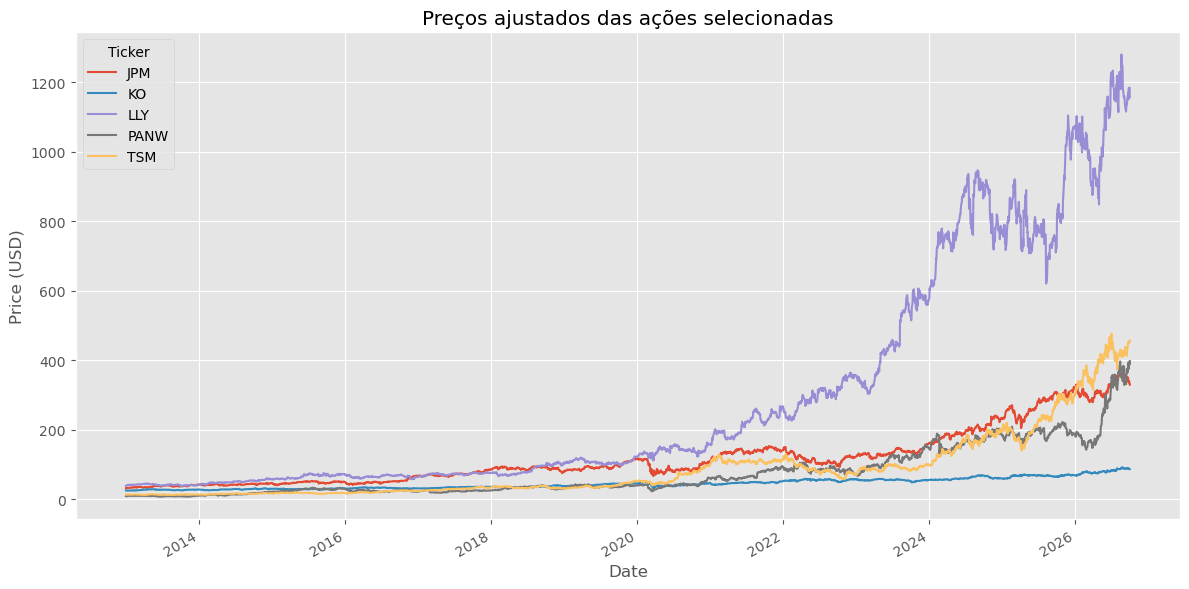

In [3]:
prices = download_prices(TICKERS, START_DATE, END_DATE)
validate_prices(prices, TICKERS, END_DATE)

print("Primeira data:", prices.index.min().date(), "| Última data:", prices.index.max().date())
display(prices.tail())
P.plot_prices(prices, save_path=FIGS / "01_precos.png")

## 2. Retornos e benchmark

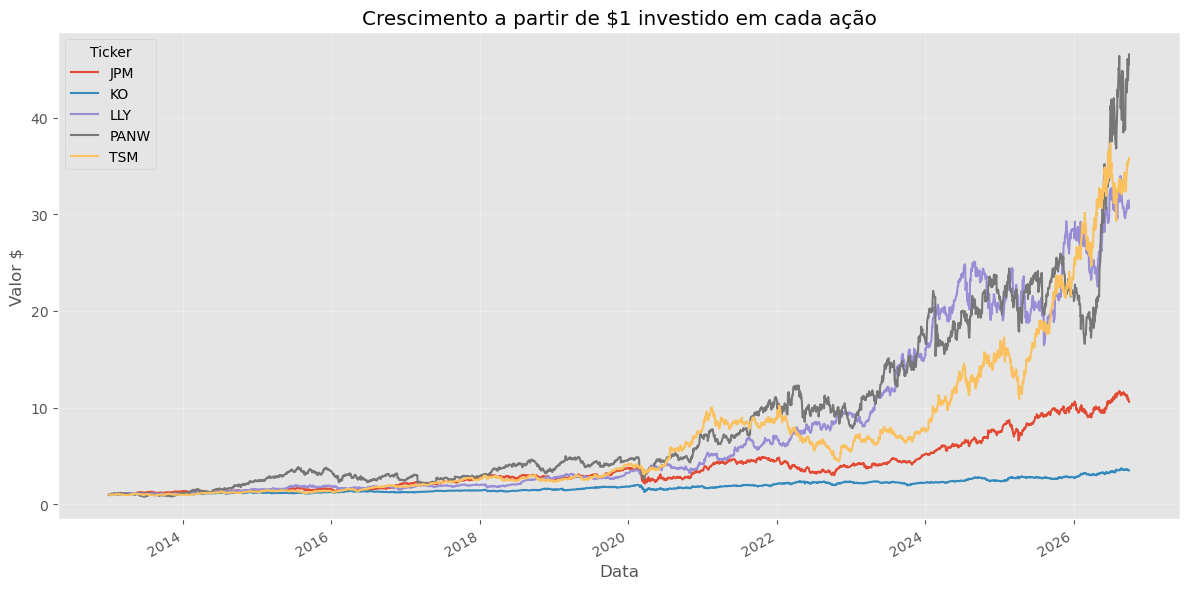

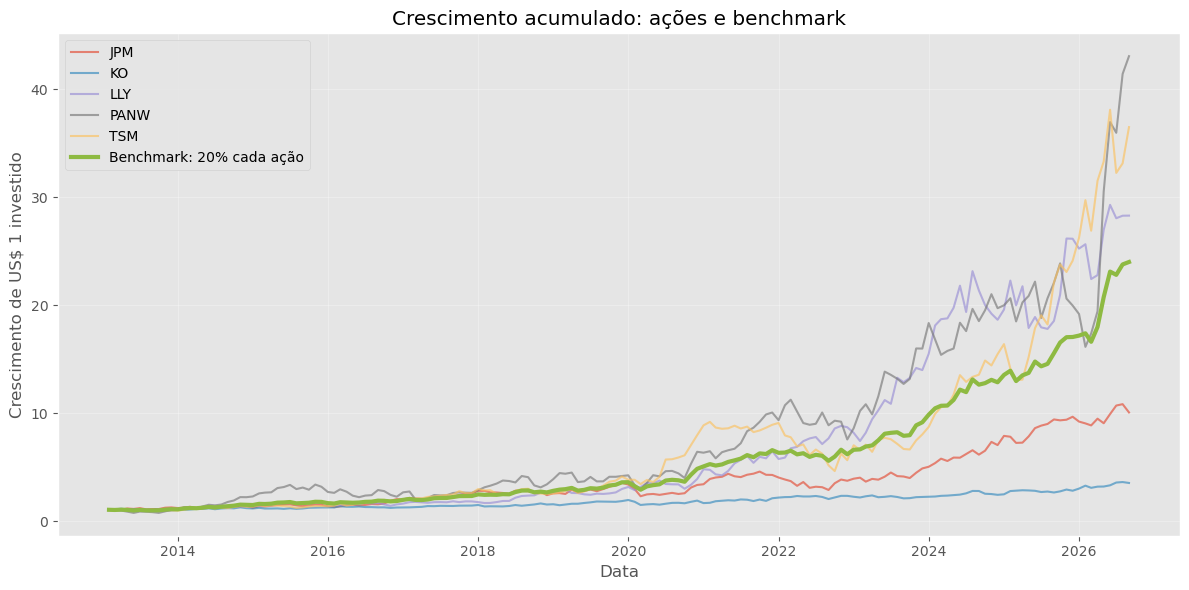

In [4]:
daily_returns = R.daily_returns(prices)
cumulative_returns = R.growth_of_one(daily_returns)
P.plot_daily_growth(cumulative_returns, save_path=FIGS / "02_crescimento_diario.png")

monthly_prices = R.to_monthly_prices(prices)
monthly_returns = R.to_monthly_returns(monthly_prices)
benchmark_returns = R.equal_weight_benchmark(monthly_returns)

monthly_stock_growth = R.growth_of_one(monthly_returns)
benchmark_growth = R.growth_of_one(benchmark_returns)
P.plot_monthly_growth(monthly_stock_growth, benchmark_growth, save_path=FIGS / "03_acoes_benchmark.png")

## 3. Estratégia (seleção, escolha do peso no treino e carteira final)

Grade usada: 20% a 50% (31 candidatos)
Pesos escolhidos: 80% / 20% (maior Sharpe no treino)
Atenção: o melhor peso está na borda da grade testada.


,Sharpe treino,Sharpe teste (diagnóstico)
Peso da menor posição,,
0.20,1.3175,1.2369
0.21,1.3135,1.2365
0.22,1.3091,1.2359
0.23,1.3044,1.2351
0.24,1.2994,1.2340
0.25,1.2941,1.2327
0.26,1.2885,1.2311
0.27,1.2825,1.2292
0.28,1.2761,1.2271


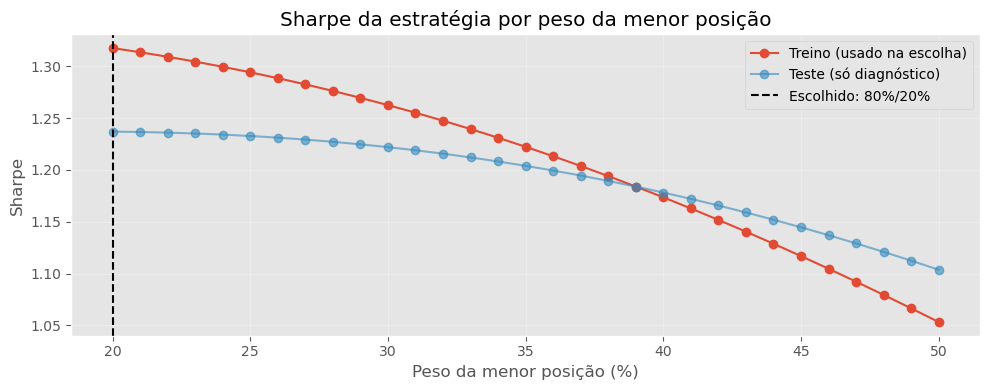

Ticker,JPM,KO,LLY,PANW,TSM
Date,,,,,
2025-10,0.2,0.0,0.0,0.0,0.8
2025-11,0.2,0.0,0.0,0.0,0.8
2025-12,0.0,0.0,0.2,0.0,0.8
2026-01,0.0,0.0,0.8,0.0,0.2
2026-02,0.0,0.0,0.8,0.0,0.2
2026-03,0.0,0.0,0.2,0.0,0.8
2026-04,0.0,0.0,0.2,0.0,0.8
2026-05,0.0,0.2,0.0,0.0,0.8
2026-06,0.0,0.0,0.0,0.8,0.2


In [5]:
# A grade de pesos (menor posição de 20% a 50%) vem do config.py
out = S.run_strategy(prices, RF_MONTHLY, TRAIN_END)

grid = out["weight_table"].index
print(f"Grade usada: {grid.min():.0%} a {grid.max():.0%} ({len(grid)} candidatos)")

weights = out["weights"]
strategy_returns = out["strategy_returns"]
MIN_WEIGHT, TOP_WEIGHT = out["min_weight"], out["top_weight"]
STRATEGY_LABEL = S.strategy_label(MIN_WEIGHT)

print(f"Pesos escolhidos: {TOP_WEIGHT:.0%} / {MIN_WEIGHT:.0%} (maior Sharpe no treino)")
if MIN_WEIGHT in (grid.min(), grid.max()):
    print("Atenção: o melhor peso está na borda da grade testada.")
display(out["weight_table"].round(4))
P.plot_weight_search(out["weight_table"], MIN_WEIGHT, save_path=FIGS / "04_busca_de_pesos.png")
display(weights.tail(12))

In [6]:
# Validação da carteira: sempre 2 ações, 100% investido, sem alavancagem
active = weights.loc[weights.sum(axis=1) > 0]
assert np.allclose(active.sum(axis=1), 1.0)
assert ((active > 0).sum(axis=1) == 2).all()
assert (weights >= 0).all().all()
print("Meses investidos:", len(active), "| Meses sem alocação:", len(weights) - len(active))

Meses investidos: 158 | Meses sem alocação: 7


## 4. Estratégia vs. benchmark

Meses de treino: 94 | Meses de teste: 63


,Estrategia,Benchmark
Meses,94.000000,94.000000
Retorno acumulado,9.392791,4.658242
Retorno anualizado,0.348328,0.247633
Volatilidade anualizada,0.216962,0.156724
Máximo drawdown,-0.136258,-0.193696
Sharpe,1.317518,1.250341


,Estrategia,Benchmark
Meses,63.000000,63.000000
Retorno acumulado,3.774292,3.264266
Retorno anualizado,0.346840,0.318167
Volatilidade anualizada,0.232922,0.170539
Máximo drawdown,-0.178489,-0.150701
Sharpe,1.236887,1.490073


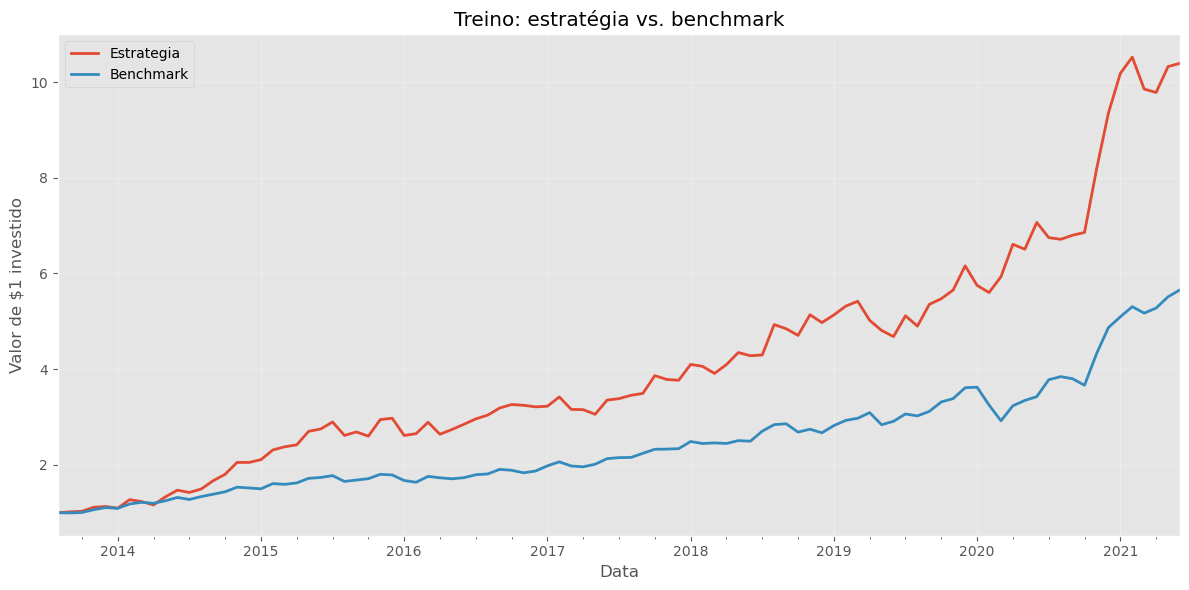

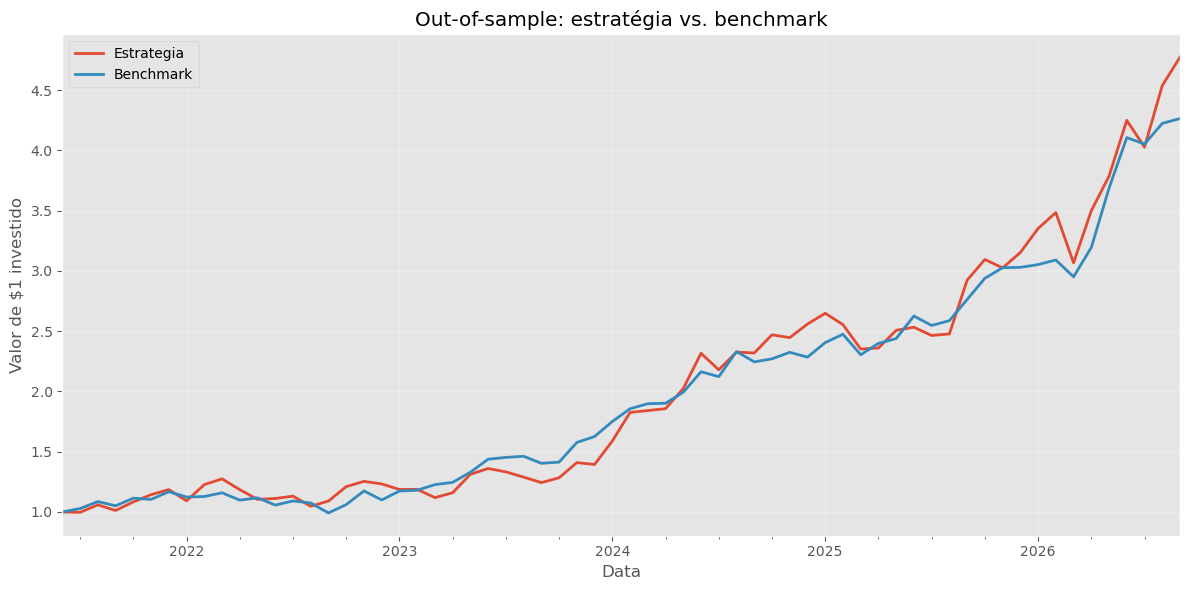

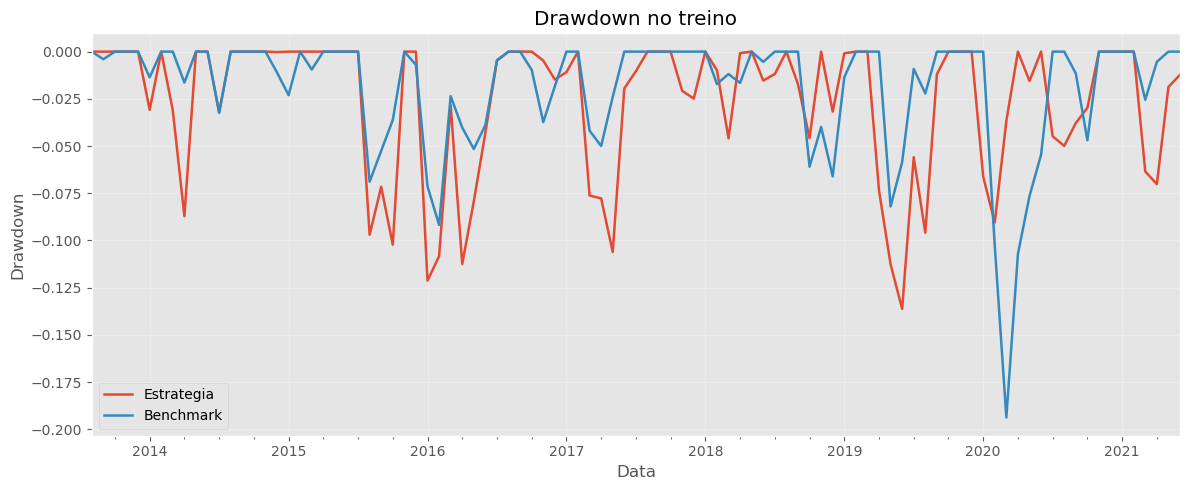

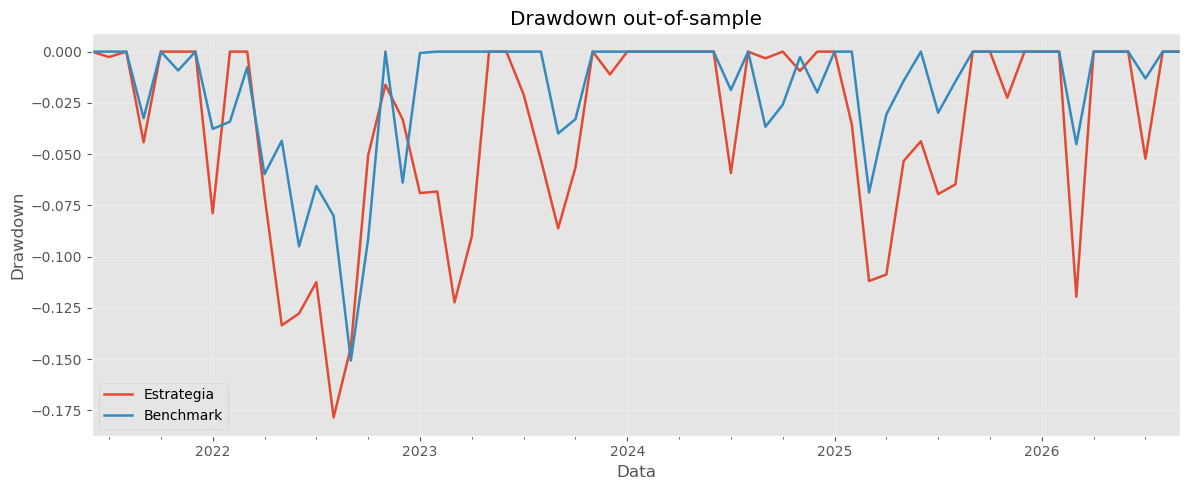

In [7]:
comparison = pd.concat(
    [strategy_returns.rename("Estrategia"), benchmark_returns.rename("Benchmark")], axis=1
).dropna()
train_comparison, test_comparison = M.split_train_test(comparison, TRAIN_END)
print("Meses de treino:", len(train_comparison), "| Meses de teste:", len(test_comparison))

metrics_train = M.metrics_table(train_comparison, RF_MONTHLY)
metrics_test = M.metrics_table(test_comparison, RF_MONTHLY)
display(metrics_train)
display(metrics_test)
metrics_train.to_csv(TABLES / "metricas_treino.csv")
metrics_test.to_csv(TABLES / "metricas_teste.csv")

P.plot_growth(train_comparison, "Treino: estratégia vs. benchmark", save_path=FIGS / "05_crescimento_treino.png")
P.plot_growth(test_comparison, "Out-of-sample: estratégia vs. benchmark", save_path=FIGS / "06_crescimento_teste.png")
P.plot_drawdown(train_comparison, "Drawdown no treino", save_path=FIGS / "07_drawdown_treino.png")
P.plot_drawdown(test_comparison, "Drawdown out-of-sample", save_path=FIGS / "08_drawdown_teste.png")

## 5. Referência: S&P 500 (SPY)

,Estrategia 80/20,Benchmark 5 ativos,S&P 500 (proxy SPY)
Meses,94.000000,94.000000,94.000000
Retorno acumulado,9.392791,4.658242,2.048661
Retorno anualizado,0.348328,0.247633,0.152925
Volatilidade anualizada,0.216962,0.156724,0.136068
Máximo drawdown,-0.136258,-0.193696,-0.194477
Sharpe,1.317518,1.250341,0.830803


,Estrategia 80/20,Benchmark 5 ativos,S&P 500 (proxy SPY)
Meses,63.000000,63.000000,63.000000
Retorno acumulado,3.774292,3.264266,0.910937
Retorno anualizado,0.346840,0.318167,0.131282
Volatilidade anualizada,0.232922,0.170539,0.155264
Máximo drawdown,-0.178489,-0.150701,-0.239272
Sharpe,1.236887,1.490073,0.621844


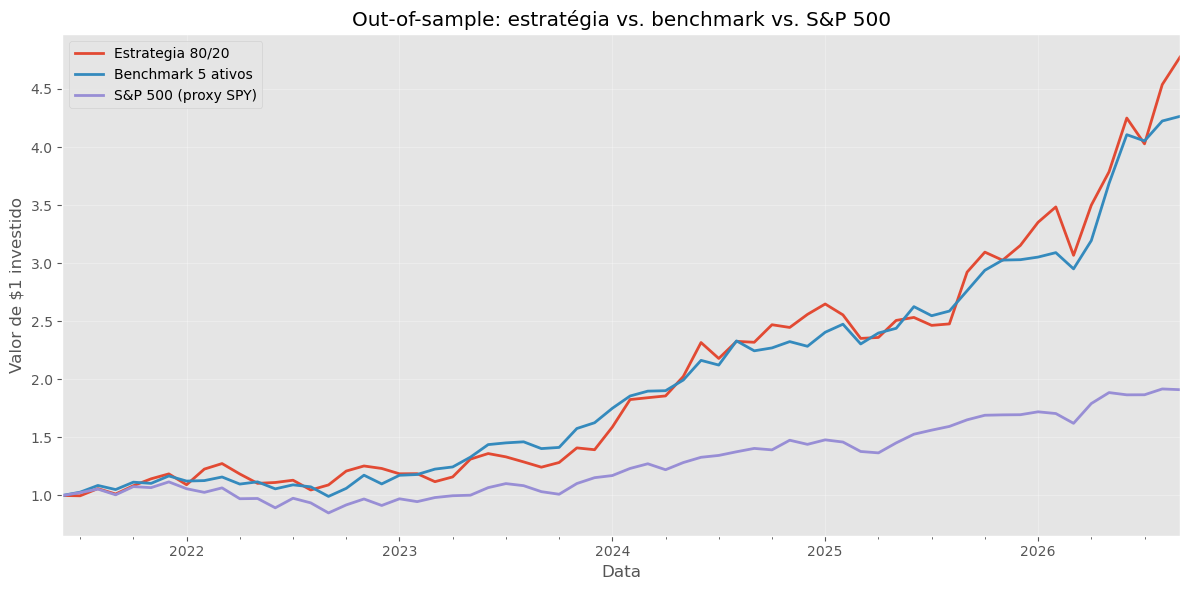

In [8]:
spy_prices = download_prices(["SPY"], START_DATE, END_DATE)["SPY"]
assert spy_prices.index.max().to_period("M") == prices.index.max().to_period("M")
spy_returns = R.to_monthly_returns(R.to_monthly_prices(spy_prices))

comparison_all = pd.concat(
    [strategy_returns.rename(STRATEGY_LABEL),
     benchmark_returns.rename("Benchmark 5 ativos"),
     spy_returns.rename("S&P 500 (proxy SPY)")],
    axis=1, join="inner",
).dropna()
comparison_train, comparison_test = M.split_train_test(comparison_all, TRAIN_END)

display(M.metrics_table(comparison_train, RF_MONTHLY))
display(M.metrics_table(comparison_test, RF_MONTHLY))
P.plot_growth(comparison_test, "Out-of-sample: estratégia vs. benchmark vs. S&P 500", save_path=FIGS / "09_teste_com_spy.png")

## 6. Robustez: primeira e segunda metade

In [9]:
display(RB.compare_halves(comparison_train, "Treino", RF_MONTHLY))
display(RB.compare_halves(comparison_test, "Teste", RF_MONTHLY))

Treino - primeira metade                     \
                                Estrategia 80/20 Benchmark 5 ativos   
Meses                                  47.000000          47.000000   
Retorno acumulado                       2.384795           1.151998   
Retorno anualizado                      0.365211           0.216133   
Volatilidade anualizada                 0.223703           0.126340   
Máximo drawdown                        -0.121226          -0.091757   
Sharpe                                  1.341250           1.311807   

                                            Treino - segunda metade  \
                        S&P 500 (proxy SPY)        Estrategia 80/20   
Meses                             47.000000               47.000000   
Retorno acumulado                  0.634330                2.070434   
Retorno anualizado                 0.133626                0.331654   
Volatilidade anualizada            0.098880                0.212345   
Máximo drawdown                   -0.084911               -0.136258   
Sharpe                             0.925745                1.279329   

                                                                
                        Benchmark 5 ativos S&P 500 (proxy SPY)  
Meses                            47.000000           47.000000  
Retorno acumulado                 1.629297            0.865389  
Retorno anualizado                0.279950            0.172553  
Volatilidade anualizada           0.183143            0.166059  
Máximo drawdown                  -0.193696           -0.194477  
Sharpe                            1.235007            0.810279

Teste - primeira metade                     \
                               Estrategia 80/20 Benchmark 5 ativos   
Meses                                 31.000000          31.000000   
Retorno acumulado                      0.589054           0.750789   
Retorno anualizado                     0.196355           0.242096   
Volatilidade anualizada                0.217268           0.173860   
Máximo drawdown                       -0.178489          -0.150701   
Sharpe                                 0.752990           1.115295   

                                            Teste - segunda metade  \
                        S&P 500 (proxy SPY)       Estrategia 80/20   
Meses                             31.000000              32.000000   
Retorno acumulado                  0.171621               2.004488   
Retorno anualizado                 0.063230               0.510650   
Volatilidade anualizada            0.185390               0.245519   
Máximo drawdown                   -0.239272              -0.119598   
Sharpe                             0.209580               1.664657   

                                                                
                        Benchmark 5 ativos S&P 500 (proxy SPY)  
Meses                            32.000000           32.000000  
Retorno acumulado                 1.435625            0.631020  
Retorno anualizado                0.396301            0.201357  
Volatilidade anualizada           0.168286            0.120028  
Máximo drawdown                  -0.068729           -0.075790  
Sharpe                            1.856628            1.270061

## 7. Turnover e custos de transação

In [10]:
turnover = C.monthly_turnover(weights, strategy_returns.index)
display(C.turnover_summary(turnover))

cost_table_train = C.evaluate_transaction_costs(strategy_returns, turnover, TRAIN_END, "train", RF_MONTHLY)
cost_table_test = C.evaluate_transaction_costs(strategy_returns, turnover, TRAIN_END, "test", RF_MONTHLY)
print("Custos no treino"); display(cost_table_train)
print("Custos no teste"); display(cost_table_test)
cost_table_train.to_csv(TABLES / "custos_treino.csv")
cost_table_test.to_csv(TABLES / "custos_teste.csv")

Turnover médio mensal      0.249091
Turnover mediano mensal    0.200000
Turnover máximo mensal     1.000000
dtype: float64

Custos no treino


,0 bps,5 bps,10 bps,25 bps
Meses,94.000000,94.000000,94.000000,94.000000
Retorno acumulado,9.392791,9.153843,8.920248,8.250431
Retorno anualizado,0.348328,0.344330,0.340342,0.328434
Volatilidade anualizada,0.216962,0.217026,0.217095,0.217333
Máximo drawdown,-0.136258,-0.136436,-0.136613,-0.137146
Sharpe,1.317518,1.303188,1.288836,1.245661


Custos no teste


,0 bps,5 bps,10 bps,25 bps
Meses,63.000000,63.000000,63.000000,63.000000
Retorno acumulado,3.774292,3.694185,3.615372,3.386496
Retorno anualizado,0.346840,0.342506,0.338183,0.325281
Volatilidade anualizada,0.232922,0.232847,0.232776,0.232599
Máximo drawdown,-0.178489,-0.179801,-0.181113,-0.185041
Sharpe,1.236887,1.223055,1.209186,1.167360


## 8. Gráfico final

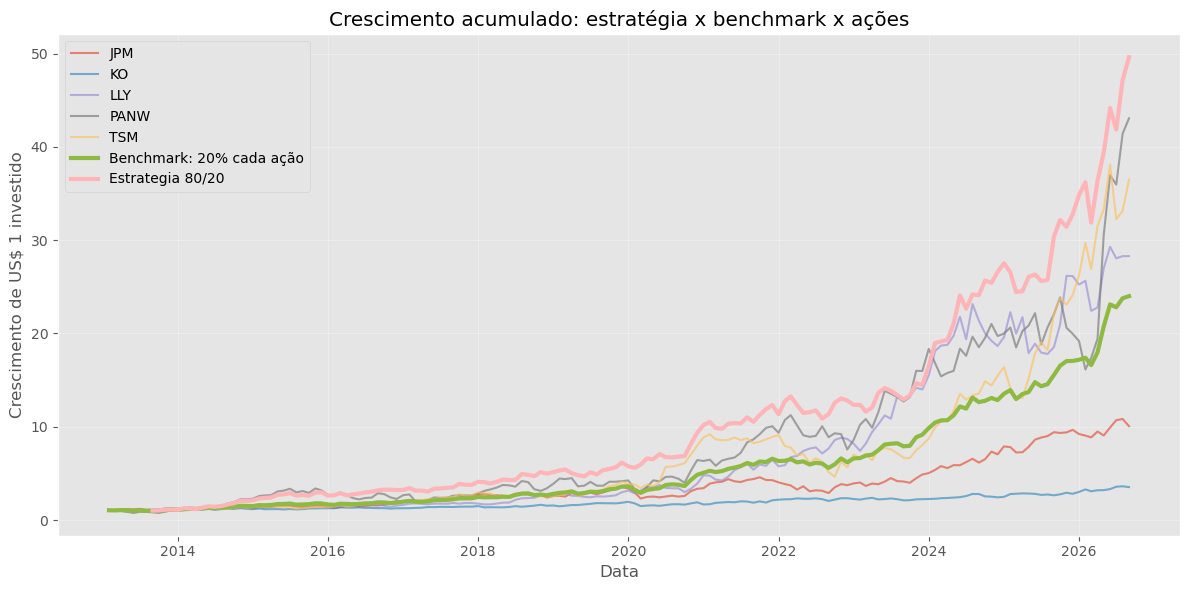

In [11]:
strategy_growth = R.growth_of_one(strategy_returns.dropna())
P.plot_monthly_growth(monthly_stock_growth, benchmark_growth, strategy_growth,
                      strategy_label=STRATEGY_LABEL, save_path=FIGS / "10_final.png")